# Testing for hdps.catalogs: classes to build & load AIC Refcat.  

This notebook contains testing & comparisons of methods for various aspects of the AICRefcat and AICRefcatBuilder classes.  

See hdps.catalogs README for more information on AIC Refcat and how it fits into AIC.  

**AIC Refcat** is a catalog of known sources that will be observed by Argus; minipix cutouts of these sources will be saved long-term (this minipix list is AIC Base, which is also built/handled by this package.)
- contains only the "constant" "static" point sources & extended objects to save in Argus observations
- will be constructed from multiple constituent reference catalogs (further testing required as of 2026/05):
    - ATLAS-Refcat2 Stellar Reference Catalog
        - for sources g <= 19 mag
        - only contains stars (with some galaxy contamination)
    - Gaia Galaxy Candidates
        - for sources G <= 19 mag (still needs testing)
        - to supplement ATLAS-Refcat2, which does not contain galaxies
    - PanSTARRS
        - for sources g > 19 mag
        - contains both stars and galaxies
- Built by the `AICRefcatBuilder` class, loaded by `AICRefcat` class.  `AICRefcatBuilder` does the following:
    - loads all sources of interest with lsdb
    - identifies minipix/tile IDs for each source, if not already calculated & saved
    - writes catalog with IDs to disk, if not already saved



*for Katie: I am using my hdps jupyter kernel*

Outdated info: ~~You will need to install hdps and work within the virtual environment; otherwise, you must install lsdb: `# uv pip install "lsdb[full]>=0.8.2"`~~

<u>**Color Key:**</u>

- <font color='#3d85c6'>.Blue '#3d85c6': Heading 1</font>
- <font color='#6aa84f'>..Green '#6aa84f': Heading 2</font>
- <font color='#f1c232'>...Yellow '#f1c232': Heading 3</font>
- <font color='#e69138'>Orange '#e69138': guiding comments</font>
- Black: exposition

.#### '#3d85c6' .blue
.#### '#6aa84f' ..green
.#### '#f1c232' ...yellow
.#### '#e69138' orange

# <font color="#3d85c6">.General Tests</font>

In [1]:
# Imports

import astropy.units as u
from dask.distributed import Client
from dask import dataframe as dfdask
from dataclasses import dataclass
from hdps.skymap import TanSegmentLookup
import lsdb
from lsdb.nested.datasets import generate_data
from lsdb.streams import CatalogStream
import numpy as np
import pandas as pd
import pyarrow as pa # idk if this is actually necessary

## <font color="#6aa84f">..`lsdb` dataframe methods</font>
<font color="#e69138">Generate a toy catalog:</font>

In [ ]:
nf = generate_data(1000, 5, seed=0, ra_range=(0.0, 300.0), dec_range=(-50.0, 50.0))
df = nf.compute()[["ra", "dec", "id"]]
catalog = lsdb.from_dataframe(df, catalog_name="toy_catalog")
catalog

,ra,dec,id
npartitions=12,,,
"Order: 0, Pixel: 0",double[pyarrow],double[pyarrow],int64[pyarrow]
"Order: 0, Pixel: 1",...,...,...
...,...,...,...
"Order: 0, Pixel: 10",...,...,...
"Order: 0, Pixel: 11",...,...,...


### <font color="#f1c232">...Creating a meta</font>

<font color="#e69138">Create meta (empty pandas dataframe) from catalog columns & dtypes:</font>

In [13]:
df_cols = list(catalog.columns)
df_dtypes = list(catalog.dtypes)

meta = pd.DataFrame({col: pd.Series(dtype=dtp) for col,dtp in zip(df_columns,df_dtypes)})

meta

,ra,dec,id


<font color="#e69138">Can also create meta from scratch:</font>

In [ ]:
df_columns = ['ra', 'dec', "id"]
df_dtypes = ["int64[pyarrow]","float64[pyarrow]","float64[pyarrow]"]
df_meta = pd.DataFrame({col: pd.Series(dtype=dtp) for col,dtp in zip(df_columns,df_dtypes)})
df_meta

,ra,dec,id


# <font color='#3d85c6'>.Testing Methods to Build/Load AIC Refcat</font>

Code to build the following catalogs:
- AIC Refcat 
    - source catalog of every "non-moving" "point" source with "constant" magnitude
    - built with `AICRefcat` class

AIC Refcat includes all the "static" non-moving, non-transient, point sources from various constituent reference catalogs; it will be used to build AIC Base.  Transients & moving objects & requests from sci team are covered by other parts of AIC.

**What needs to happen**

This package should have the functionality to build and load AIC Refcat.
- "build" AIC Refcat means get all the appropriate sources from a selection of reference catalogs
    - input should be:
        - the reference catalogs (where they are and their path/url)
        - Argus's coordinate & magnitude limits
        - which columns to get from each refcat and what their common names will be in AIC Refcat
        - parameters for a sky tiling scheme for the TanSeg Lookup to get minipix indices, and where to save AIC Refcat on disk.
    - output should be:
        - a full combined reference catalog of sources and their associated minipix indices (AIC Refcat) written to disk in HATS format.
- Build Steps:
    - take a selection of reference catalogs
    - select sources within the Argus FoV (dec > -20 deg) and single-epoch limiting mag (g > 21)
    - identify minipix in which refcat sources are found, i.e. get minipix/tanseg indices 
    - save combination of refcat sources & minipix/tanseg IDs as AIC Refcat 
  


**Tools & Methods Overview**

The main "issue" is that the constituent reference catalogs, & therefore AIC Refcat, are on the order of 1 billion rows; any analysis performed on/with these cats in a timely manner will have to be done in parallel.  LINCC's __[LSDB](https://github.com/astronomy-commons/lsdb)__ package (build around Dask) provides these tools.  Catalogs are lazily loaded as Dask __[DataFrames](https://docs.dask.org/en/stable/dataframe.html)__, and you can plan computations and execute them whenever is convenient.

I use LSDB to open/interact with catalogs in HATS format, separated into partitions which have roughly equal amounts of sources.  I will put whatever constituent reference catalogs we need to use into HATS format for speedy access/usage (if they are not already available in HATS format).  These constituents are either be on-disk (ATLAS-Refcat2), or accessed externally if they are available on the LSDB data cloud (Pan-STARRS and Gaia).  AIC Refcat will be saved to disk.  

## <font color='#6aa84f'>..Testing Setup</font>

<font color="#e69138">Load in some reference catalogs with and without filters imposed on rows/columns, and make some metas:</font>

In [ ]:
# Load catalogs and create metas with LSDB for testing purposes
scratch_path = "/net/scratch/kmfas/"

#--------------
# ATLAS-Refcat2 
# this is the 0.1 fraction of ATLAS that Katie HATS-ed on Aurora
#--------------
atlas_path = scratch_path+"atlas_refcat2/atlas_0_01" # on Aurora
atlas_filters = [["g","<=",19],["dec",">=",-20]]

# full catalog, lazily-loaded
atlas_frac = lsdb.open_catalog(atlas_path) # atlas_full -> atlas_frac
print("Lazily loaded full fractional ATLAS-Refcat2 catalog (atlas_frac)")
meta_atlas = dfdask.utils.make_meta(atlas_frac.head(1))

# full catalog, lazily-loaded, with filters
atlas_frac_filtered = lsdb.open_catalog(atlas_path,filters=atlas_filters)
print("Lazily loaded full fractional filtered ATLAS-Refcat2 catalog (atlas_frac_filtered)")

# single partition, fully-loaded
ordr = 5#3     # healpix order of partition you want (I looked this pair up in my notebook for testing mapping functions to partitions with LSDB)
pixid = 5888#368  # ID of partition you want
atlas_pix_lookup = lsdb.open_catalog(atlas_path,search_filter=lsdb.PixelSearch((ordr,pixid)))
atlas_single_part = atlas_pix_lookup.compute()
print("Loaded single partition of fractional ATLAS-Refcat2 catalog (atlas_single_part)")


#------------------------
# PanSTARRS Objects table 
# available through LSDB data cloud: https://data.lsdb.io/#Pan-STARRS/Pan-STARRS1_(objects)
# column information: https://outerspace.stsci.edu/spaces/PANSTARRS/pages/298812394/PS1+Database+object+and+detection+tables 
#------------------------
#ps_path = 's3://stpubdata/panstarrs/ps1/public/hats/otmo' # on lsdb data cloud
ps_path = scratch_path+"panstarrs/" # on Aurora
ps_filters = [["gMeanApMag",">",19],["gMeanApMag","<=",21],["decMean",">=",-20]]
ps_columns = ["objID","raMean","decMean","raMeanErr","decMeanErr",
              "pmra","pmdec","pmraErr","pmdecErr",
              "gMeanApMag","gMeanApMagErr",
              "rMeanApMag","rMeanApMagErr",
              "iMeanApMag","iMeanApMagErr"]

# full catalog, lazily-loaded
ps_full = lsdb.open_catalog(ps_path,colums=ps_columns)
print("Lazily loaded full Pan-STARRS objects catalog (ps_full)")

# full catalog, lazily-loaded, with filters
ps_full_filtered = lsdb.open_catalog(ps_path,columns=ps_columns,filters=ps_filters)
print("Lazily loaded full filtered Pan-STARRs objects catalog (ps_full_filtered)")
# create meta
meta_ps = dfdask.utils.make_meta(ps_full_filtered.head(1))
# create meta
ps_minipix_columns = ['objID', 'raMean', 'decMean', 'raMeanErr', 'decMeanErr', 'pmra', 'pmdec', 'pmraErr', 'pmdecErr', 'gMeanApMag', 'gMeanApMagErr', 'rMeanApMag', 'rMeanApMagErr', 'iMeanApMag', 'iMeanApMagErr', 'tanseg_id', 'local_idx']
ps_minipix_dtypes = ["int64[pyarrow]","double[pyarrow]","double[pyarrow]","double[pyarrow]","double[pyarrow]","double[pyarrow]","double[pyarrow]","double[pyarrow]","double[pyarrow]","double[pyarrow]","double[pyarrow]","double[pyarrow]","double[pyarrow]","double[pyarrow]","double[pyarrow]","int32","int16"]
scratch_meta_ps_minipix = pd.DataFrame({col: pd.Series(dtype=dtp) for col,dtp in zip(ps_minipix_columns,ps_minipix_dtypes)})


#------------------
# ZTF objects table 
# (because it's a full sized HATSed catalog of similar row count to ATLAS, for testing purposes)
# available through LSDB data cloud: https://data.lsdb.io/#ZTF/ZTF_DR14_(objects) 
#------------------
ztf_path = "https://data.lsdb.io/hats/ztf_dr14"

# full catalog, lazily-loaded
ztf_full = lsdb.open_catalog(ztf_path)
print("Lazily loaded full ZTF DR14 Objects catalog (ztf_full)")

# full catalog, lazily-loaded, with filters 
ztf_full_filtered = lsdb.open_catalog(ztf_path,columns=[],filters=[["mean_mag_g","<=",20.5],["dec",">",-20]])
print("Lazily loaded full filtered ZTF DR14 Objects catalog (ztf_full_filtered)")

Lazily loaded full fractional ATLAS-Refcat2 catalog (atlas_frac)
Lazily loaded full fractional filtered ATLAS-Refcat2 catalog (atlas_frac_filtered)


Computing Catalog:   0%|          | 0/3 [00:00<?, ?it/s]

Loaded single partition of fractional ATLAS-Refcat2 catalog (atlas_single_part)
Lazily loaded full Pan-STARRS objects catalog (ps_full)
Lazily loaded full filtered Pan-STARRs objects catalog (ps_full_filtered)
Lazily loaded full ZTF DR14 Objects catalog (ztf_full)
Lazily loaded full filtered ZTF DR14 Objects catalog (ztf_full_filtered)


In [12]:
ps_path = 's3://stpubdata/panstarrs/ps1/public/hats/otmo' # on lsdb data cloud

ps = lsdb.open_catalog(ps_path,columns="all")#"/net/scratch/kmfas/panstarrs",columns="all")

In [13]:
ps

,objName,objNameHMS,objAltName1,objAltName2,objAltName3,objPopularName,objID,uniquePspsOBid,ippObjID,surveyID,htmID,zoneID,tessID,projectionID,skyCellID,randomID,batchID,dvoRegionID,processingVersion,objInfoFlag,astrometryCorrectionFlag,qualityFlag,raStack,decStack,raStackErr,decStackErr,raMean,decMean,raMeanErr,decMeanErr,pmra,pmdec,pmraErr,pmdecErr,epochMean,posMeanChisq,cx,cy,cz,lambda,beta,l,b,nStackObjectRows,nStackDetections,nDetections,ng,nr,ni,nz,ny,gQfPerfect,gMeanPSFMag,gMeanPSFMagErr,gMeanPSFMagStd,gMeanPSFMagNpt,gMeanPSFMagMin,gMeanPSFMagMax,gMeanKronMag,gMeanKronMagErr,gMeanKronMagStd,gMeanKronMagNpt,gMeanApMag,gMeanApMagErr,gMeanApMagStd,gMeanApMagNpt,gFlags,rQfPerfect,rMeanPSFMag,rMeanPSFMagErr,rMeanPSFMagStd,rMeanPSFMagNpt,rMeanPSFMagMin,rMeanPSFMagMax,rMeanKronMag,rMeanKronMagErr,rMeanKronMagStd,rMeanKronMagNpt,rMeanApMag,rMeanApMagErr,rMeanApMagStd,rMeanApMagNpt,rFlags,iQfPerfect,iMeanPSFMag,iMeanPSFMagErr,iMeanPSFMagStd,iMeanPSFMagNpt,iMeanPSFMagMin,iMeanPSFMagMax,iMeanKronMag,iMeanKronMagErr,iMeanKronMagStd,iMeanKronMagNpt,iMeanApMag,iMeanApMagErr,iMeanApMagStd,iMeanApMagNpt,iFlags,zQfPerfect,zMeanPSFMag,zMeanPSFMagErr,zMeanPSFMagStd,zMeanPSFMagNpt,zMeanPSFMagMin,zMeanPSFMagMax,zMeanKronMag,zMeanKronMagErr,zMeanKronMagStd,zMeanKronMagNpt,zMeanApMag,zMeanApMagErr,zMeanApMagStd,zMeanApMagNpt,zFlags,yQfPerfect,yMeanPSFMag,yMeanPSFMagErr,yMeanPSFMagStd,yMeanPSFMagNpt,yMeanPSFMagMin,yMeanPSFMagMax,yMeanKronMag,yMeanKronMagErr,yMeanKronMagStd,yMeanKronMagNpt,yMeanApMag,yMeanApMagErr,yMeanApMagStd,yMeanApMagNpt,yFlags
npartitions=9577,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
"Order: 5, Pixel: 0",string[pyarrow],string[pyarrow],string[pyarrow],string[pyarrow],string[pyarrow],string[pyarrow],int64[pyarrow],int64[pyarrow],int64[pyarrow],int16[pyarrow],int64[pyarrow],int32[pyarrow],int16[pyarrow],int16[pyarrow],int16[pyarrow],double[pyarrow],int64[pyarrow],int32[pyarrow],int16[pyarrow],int32[pyarrow],int32[pyarrow],int16[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],int16[pyarrow],int16[pyarrow],int16[pyarrow],int16[pyarrow],int16[pyarrow],int16[pyarrow],int16[pyarrow],int16[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],int16[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],int16[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],int16[pyarrow],int32[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],int16[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],int16[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],int16[pyarrow],int32[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],int16[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],int16[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],int16[pyarrow],int32[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],int16[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],int16[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],int16[pyarrow],int32[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],int16[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],int16[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],int16[pyarrow],int32[pyarrow]
"Order: 5, Pixel: 1",...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,

/home/kmfas/hdps/.venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:2599: RuntimeWarning: invalid value encountered in do_format (vectorized)
  outputs = ufunc(*args, out=...)
/home/kmfas/hdps/.venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:2599: RuntimeWarning: invalid value encountered in do_format (vectorized)
  outputs = ufunc(*args, out=...)


(<Figure size 1000x500 with 2 Axes>,
 <WCSAxes: title={'center': 'Catalog pixel map - otmo'}>)

/home/kmfas/hdps/.venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:2599: RuntimeWarning: invalid value encountered in do_format (vectorized)
  outputs = ufunc(*args, out=...)
/home/kmfas/hdps/.venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:2599: RuntimeWarning: invalid value encountered in do_format (vectorized)
  outputs = ufunc(*args, out=...)
/home/kmfas/hdps/.venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:2599: RuntimeWarning: invalid value encountered in do_format (vectorized)
  outputs = ufunc(*args, out=...)
/home/kmfas/hdps/.venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:2599: RuntimeWarning: invalid value encountered in do_format (vectorized)
  outputs = ufunc(*args, out=...)


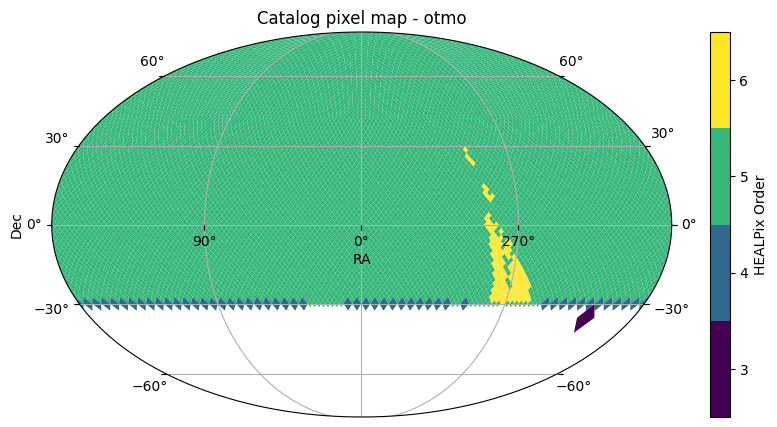

In [8]:
ps.plot_pixels()

<font color="#e69138">Define a TanSegment lookup with hdps.skymap to look up minipix/tanseg IDS (will be used by AICRefcat):</font>

In [9]:
# Define a TanSegment lookup with hdps_skymap to get minipix/tanseg IDs

# define sky tiling parameters
tile_size_arcsec = 1800.0  
overlap_arcsec = 28.125
pixel_scale = 900/1024 # pixels/arcsec, math comes out to 0.87890625 

# define the lookup
lookup = TanSegmentLookup(
    spacing_deg=(tile_size_arcsec-overlap_arcsec)/3600, # (tile_size - overlap) in degrees
    pixel_scale_deg=pixel_scale/3600                    # arcsec to degrees
) 
print(f"Defined a TanSegmentLookup ''lookup'' with sky tiling parameters:\n    tile size {tile_size_arcsec}''\n    overlap {overlap_arcsec}''\n    pixel scale {pixel_scale}''/pixel")

Defined a TanSegmentLookup ''lookup'' with sky tiling parameters:
    tile size 1800.0''
    overlap 28.125''
    pixel scale 0.87890625''/pixel


<font color="#e69138">Define a couple Tansegment Activation Managers to test out minipix activation (initializing catalogs):</font> 

In [16]:
# Define TanSegment Activation managers to activate minipix (initializing catalog)


minipix_path_0 = scratch_path+"test_minipix/data0/aic_base_minipix/"
manager0 = TanSegmentActivationManager(minipix_path_0)

minipix_path_1 = scratch_path+"test_minipix/data1/aic_base_minipix/"
manager1 = TanSegmentActivationManager(minipix_path_1)

print("Defined a TanSegmentActivationManager ''manager0'' pointing to ",minipix_path_0)
print("Defined a TanSegmentActivationManager ''manager1'' pointing to ",minipix_path_1)

Defined a TanSegmentActivationManager ''manager0'' pointing to  /net/scratch/kmfas/test_minipix/data0/aic_base_minipix/
Defined a TanSegmentActivationManager ''manager1'' pointing to  /net/scratch/kmfas/test_minipix/data1/aic_base_minipix/


## <font color='#6aa84f'>..Testbed</font>

### <font color='#f1c232'>...Looking up minipix/tile IDs for refcat sources with lsdb.map_partitions()</font>

This package should have the functionality to look up the minipix that contain sources from a reference catalog.

**What needs to happen:**

As stated, I use LSDB to open catalogs in HATSed format.  The reference catalogs will naturally not have columns for tanseg/minipix IDs, since this is something created for Argus data.  Therefore, `AICRefcatBuilder` should retrieve tanseg/minipix IDs for all refcat sources, & add columns with those IDs to the refcat dataframes *(and save them once so they don't have to be computed repeatedly?  Check to see if those columns are included, create them if not, and re-write the catalog if it's saved to disk.  What about catalogs accessed thru the cloud?  Should we just be saving the entire refcat selection to disk?  Where?)*

What is needed is a function that can find those minipix/tile IDs for any refcat with RA,Dec columns.  The question is how to apply such a function to a ~billion-row catalog in a timely manner.  The answer is LSDB.  

LSDB lazily loads catalogs & plans computations to be executed at a specified time.  You can apply a function to all partitions using __[map_partitions()](https://docs.lsdb.io/en/latest/reference/api/lsdb.catalog.Catalog.map_partitions.html)__; such a function should accept a DataFrame as an input & return an altered DataFrame as an output.  

LSDB map_partitions() is built around the Dask map_partitions() function, accepts a lazily-loaded catalog in the form of a Nested DataFrame, and applies a function to each partition, then returns a lazy "unevaluated" result.   Executing the computation to produce the desired results can be done after map_partitions() is applied by calling __[compute()](https://docs.lsdb.io/en/latest/reference/api/lsdb.catalog.Catalog.compute.html#lsdb.catalog.Catalog.compute)__ or __[write_catalog()](https://docs.lsdb.io/en/latest/reference/api/lsdb.catalog.Catalog.write_catalog.html)__.  

<font color="#e69138">First, define a function that accepts a dataframe with RA,Dec columns, looks up tile/minipix IDs, and returns the dataframe + 2 added columns with tile/minipix IDs:</font>

In [10]:
# Define a function to lookup minipix/tile IDs for refcat sources & add appropriate columns to refcat dataframe.  
# This function should accept a dataframe as an input, and return a dataframe (with added columns) as an output.  
# This function can, and will be applied to a lazily-loaded refcat dataframe with map_partitions().

def get_minipix(refcat,lookup,ra_col="ra",dec_col="dec"):
    """
    Get tile/tanseg IDs and minipix/local indices for refcat

    Parameters
    ----------
    refcat (DataFrame)
    lookup (TanSegmentLookup)
    ra_col (str)
    dec_col (str)

    """
    df = refcat.copy() # to make sure the columns aren't added to the input dataframe, but to a new df to output [?]
    tanseg_ids,local_idxs = lookup.query_batch(df[ra_col],df[dec_col])
    df['tanseg_id'] = tanseg_ids
    df['local_idx'] = local_idxs
    print("get_minipix() finds: ",len(df)," sources, ",len(np.unique(df[['tanseg_id','local_idx']], axis=0))," unique minipix") # just have this line to show that if refcat is lazily loaded, nothing's actually looked up
    #print("refcat columns = ",refcat.columns)
    return df

<font color="#e69138">Make sure the function defined above *actually* works, without map_partitions() (use a fully-loaded partition of a catalog):</font>

In [12]:
# Show how the function adds new columns with tanseg/minipix IDs to a refcat in a dataframe.
atlas_single_part_minipix = get_minipix(atlas_single_part,lookup,"ra","dec")
atlas_single_part_minipix

get_minipix() finds:  9993  sources,  9920  unique minipix


,Unnamed: 0,ra,dec,parallax,pmra,pmdec,g,r,i,h32,h64,h256,tanseg_id,local_idx
_healpix_29,,,,,,,,,,,,,,
1657325513743157866,23020,90.006208,0.091356,1.13,-1.42,-0.2,17.496,16.517,16.01,5888,23552,376832,263702,200
1657325536932057554,33355,89.985974,0.09594,0.69,-0.52,5.82,17.479,16.626,16.181,5888,23552,376832,263702,203
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1661827272758578812,119567,90.013518,9.480139,1.1,5.27,-3.58,19.72,18.446,17.76,5903,23615,377855,291060,493
1661827954336513510,201498,89.947741,9.530316,1.41,1.81,0.18,20.508,19.446,18.91,5903,23615,377855,291060,949


<font color="#e69138">Make sure an empty dataframe passed to the function still returns a df with the expected columns:</font>

In [24]:
# test to make sure get_minipix() returns the right columns if given an empty dataframe
atlas_empty_minipix = get_minipix(meta_atlas,lookup,"ra","dec")
print("missing columns = ",list(set(atlas_single_part_minipix.columns)-set(atlas_empty_minipix.columns))) # should be empty
print("missing column dtypes = ",list(set(atlas_single_part_minipix.dtypes)-set(atlas_empty_minipix.dtypes))) # should be empty

get_minipix() finds:  0  sources,  0  unique minipix
missing columns =  []
missing column dtypes =  []


<font color="#e69138">Create a meta to feed to map_partitions(), to ensure output columns are as expected:</font>

In [13]:
##  create a meta for atlas+minipix_columns to give to map_partitions()
meta_atlas_minipix = dfdask.utils.make_meta(atlas_single_part_minipix.head(1))
print("the two added columns with tanseg/minipix indices will have dtype: ",list(set(meta_atlas_minipix.dtypes)-set(atlas_single_part.dtypes))) # should not be empty; this is just showing that my meta for atlas+minipix_columns indeed has the minipix columns


the two added columns with tanseg/minipix indices will have dtype:  [dtype('int16'), dtype('int32')]


<font color="#e69138">Create a meta from scratch:</font>

In [15]:
atlas_minipix_columns = ['Unnamed: 0', 'ra', 'dec', 'parallax', 'pmra', 'pmdec', 'g', 'r', 'i', 'h32', 'h64', 'h256', 'tanseg_id', 'local_idx']
#atlas_minipix_dtypes = [pa.int64(),pa.float64(),pa.float64(),pa.float64(),pa.float64(),pa.float64(),pa.float64(),pa.float64(),pa.float64(),pa.int64(),pa.int64(),pa.int64(),pa.int32(),pa.int16()]
#atlas_minipix_dtypes = ["int64","float64","float64","float64","float64","float64","float64","float64","float64","int64","int64","int64","int32","int16"]
atlas_minipix_dtypes = ["int64[pyarrow]","double[pyarrow]","float64[pyarrow]","float64[pyarrow]","float64[pyarrow]","float64[pyarrow]","float64[pyarrow]","float64[pyarrow]","float64[pyarrow]","int64[pyarrow]","int64[pyarrow]","int64[pyarrow]","int32","int16"]

scratch_meta_atlas_minipix = pd.DataFrame({col: pd.Series(dtype=dtp) for col,dtp in zip(atlas_minipix_columns,atlas_minipix_dtypes)})
scratch_meta_atlas_minipix

,Unnamed: 0,ra,dec,parallax,pmra,pmdec,g,r,i,h32,h64,h256,tanseg_id,local_idx


<font color="#e69138">Make sure the function can be applied to a lazily-loaded dataframe with map_partitions():</font>

<font color="#e69138">(a) on a full lazily-loaded catalog...</font>

In [ ]:
# Show how using map_partitions() applies the function and returns a lazily loaded dataframe with the new columns.
#   Note: The actual tanseg & minipix IDs aren't retrieved until you do a compute() or write_catalog().
#   This is how the ID lookup function will be implemented in the code.
atlas_frac_minipix = atlas_frac.map_partitions(get_minipix,lookup,"ra","dec",meta=scratch_meta_atlas_minipix)
atlas_frac_minipix

#atlas_pix_lookup_minipix = atlas_pix_lookup.map_partitions(get_minipix,lookup,"ra","dec",meta=scratch_meta_atlas_minipix)
#atlas_pix_lookup_minipix

,Unnamed: 0,ra,dec,parallax,pmra,pmdec,g,r,i,h32,h64,h256,tanseg_id,local_idx
npartitions=1,,,,,,,,,,,,,,
"Order: 5, Pixel: 5888",int64[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],int64[pyarrow],int64[pyarrow],int64[pyarrow],int32,int16


In [26]:
with Client(n_workers=1,memory_limit="20GiB",threads_per_worker=1) as client:
    atlas_frac_minipix.write_catalog(base_catalog_path="/home/kmfas/atlas_pix",catalog_name="frac")


/home/kmfas/hdps/.venv/lib/python3.12/site-packages/distributed/node.py:188: UserWarning: Port 8787 is already in use.
Perhaps you already have a cluster running?
Hosting the HTTP server on port 41461 instead
  warnings.warn(


/home/kmfas/hdps/.venv/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 17.14 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


get_minipix() finds:  284  sources,  170  unique minipix
get_minipix() finds:  385  sources,  362  unique minipix
get_minipix() finds:  294  sources,  138  unique minipix
get_minipix() finds:  732  sources,  642  unique minipix
get_minipix() finds:  642  sources,  533  unique minipix
get_minipix() finds:  258  sources,  255  unique minipix
get_minipix() finds:  190  sources,  190  unique minipix
get_minipix() finds:  272  sources,  96  unique minipix
get_minipix() finds:  851  sources,  412  unique minipix
get_minipix() finds:  341  sources,  270  unique minipix
get_minipix() finds:  252  sources,  87  unique minipix
get_minipix() finds:  381  sources,  288  unique minipix
get_minipix() finds:  242  sources,  241  unique minipix
get_minipix() finds:  938  sources,  414  unique minipix
get_minipix() finds:  313  sources,  273  unique minipix
get_minipix() finds:  573  sources,  398  unique minipix
get_minipix() finds:  766  sources,  730  unique minipix
get_minipix() finds:  723  source

2026-06-25 17:25:34,905 - distributed.nanny - INFO - Closing Nanny gracefully at 'tcp://127.0.0.1:43559'. Reason: worker-close


get_minipix() finds:  445  sources,  316  unique minipix
get_minipix() finds:  379  sources,  193  unique minipix
get_minipix() finds:  699  sources,  696  unique minipix


2026-06-25 17:25:34,908 - distributed.worker.state_machine - WARNING - Async instruction for <Task cancelled name="execute('perform_write-edf32442-5a71-497e-a62c-376b6a1215d0')" coro=<Worker.execute() done, defined at /home/kmfas/hdps/.venv/lib/python3.12/site-packages/distributed/worker_state_machine.py:3608>> ended with CancelledError
2026-06-25 17:25:34,910 - distributed.core - INFO - Received 'close-stream' from tcp://127.0.0.1:43792; closing.
2026-06-25 17:25:34,911 - distributed.scheduler - INFO - Remove worker addr: tcp://127.0.0.1:41117 name: 0 (stimulus_id='handle-worker-cleanup-1782422734.9118326')
2026-06-25 17:25:34,915 - distributed.scheduler - WARNING - Removing worker 'tcp://127.0.0.1:41117' caused the cluster to lose already computed task(s), which will be recomputed elsewhere: {'perform_write-fcc90cfd-59c0-4200-a6c7-ec2700ff663e', 'perform_write-f5f995f2-da1b-47f2-aeb5-b3e2b706cdd2', 'perform_write-ff2ae25d-79ca-4c34-a659-58db1bf25e97', 'perform_write-eec887eb-a57a-4ae

KeyboardInterrupt: 

<font color="#e69138">(b) on a full lazily-loaded catalog that was opened with filters imposed:</font>

In [ ]:
# Show how using map_partitions() works on a catalog that was filtered when opened.
atlas_frac_filtered_minipix= atlas_frac_filtered.map_partitions(get_minipix,lookup,"ra","dec",meta=meta_atlas_minipix)
atlas_frac_filtered_minipix

,Unnamed: 0,ra,dec,parallax,pmra,pmdec,g,r,i,h32,h64,h256,tanseg_id,local_idx
npartitions=21693,,,,,,,,,,,,,,
"Order: 4, Pixel: 0",int64[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],int64[pyarrow],int64[pyarrow],int64[pyarrow],int32,int16
"Order: 4, Pixel: 1",...,...,...,...,...,...,...,...,...,...,...,...,...,...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"Order: 5, Pixel: 12286",...,...,...,...,...,...,...,...,...,...,...,...,...,...
"Order: 5, Pixel: 12287",...,...,...,...,...,...,...,...,...,...,...,...,...,...


<font color="#e69138">Show that this works on a HATS-ed catalog that LSDB provides through the cloud:</font>

In [28]:
# how come for PanSTARRS, the map_partitions runs get_minipix twice?  is it run on the margin catalog as well, maybe?
ps_full_filtered_minipix = ps_full_filtered.map_partitions(get_minipix,lookup,"raMean","decMean")#,meta=test_meta_ps)
ps_full_filtered_minipix

get_minipix() finds:  0  sources,  0  unique minipix
get_minipix() finds:  0  sources,  0  unique minipix


,objID,raMean,decMean,raMeanErr,decMeanErr,pmra,pmdec,pmraErr,pmdecErr,gMeanApMag,gMeanApMagErr,rMeanApMag,rMeanApMagErr,iMeanApMag,iMeanApMagErr,tanseg_id,local_idx
npartitions=27161,,,,,,,,,,,,,,,,,
"Order: 5, Pixel: 0",int64[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],int32,int16
"Order: 5, Pixel: 1",...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"Order: 6, Pixel: 49150",...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"Order: 6, Pixel: 49151",...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...


<font color="#e69138">Create a meta for PanSTARRS:</font>

In [29]:
# make a meta with minipix columns for panstarrs 
meta_ps_minipix = dfdask.utils.make_meta(ps_full_filtered_minipix.head(1))
meta_ps_minipix

get_minipix() finds:  126921  sources,  42296  unique minipix


,objID,raMean,decMean,raMeanErr,decMeanErr,pmra,pmdec,pmraErr,pmdecErr,gMeanApMag,gMeanApMagErr,rMeanApMag,rMeanApMagErr,iMeanApMag,iMeanApMagErr,tanseg_id,local_idx
_healpix_29,,,,,,,,,,,,,,,,,


<font color="#e69138">As you can see from applying my minipix-id-lookup function to lazily loaded catalogs, no IDs are actually looked up - this happpens when you do a compute() or write_catalog() and actually load the data.  This is why I have to implement a different method for catalog initialization.....</font>

### <font color='#f1c232'>...Concatenating catalogs in HATS format with LSDB</font>

This package should have the functionality to combine multiple reference catalogs.

This pertains to AICRefcat.

**What needs to happen:**

Since AIC Refcat will pull sources from several refcats, we need a way to combine those catalogs into one catalog, then re-import the whole thing to HATS format.  It is expected that all the reference catalogs will already be in HATS format - if so, lsdb.concat() may be used.  Any other catalogs that are not HATSed will be imported to HATS.  

__[lsdb.concat()](https://docs.lsdb.io/en/latest/reference/api/lsdb.catalog.Catalog.concat.html)__ concatenates 2 catalogs aligned by HEALPix pixels, and the resulting catalog has OUTER pix alignment.  I concat all the catalogs in question, choosing which one's pixel scheme to adhere to, then after saving, re-import the catalog to HATS.  

In [16]:
# Test out concat() on some cone searches of 2 catalogs 
#   Note: you'll see that although map_partitions(get_minipix) is only applied
#   twice (to right and left cats), you see it's run 3 times.

# get right-side catalog
print("Preparing right-side catalog (ATLAS):")
atlas_cone = lsdb.open_catalog(atlas_path,search_filter=lsdb.ConeSearch(ra=40, dec=30, radius_arcsec=5000),filters=atlas_filters)
cat_right = atlas_cone#.map_partitions(get_minipix,lookup,"ra","dec") # get minipix

# get left-side catalog
print("\nPreparing left-side catalog (PanSTARRS):")
ps_cone = lsdb.open_catalog(ps_path,search_filter=lsdb.ConeSearch(ra=40, dec=30, radius_arcsec=100),filters=ps_filters,columns=ps_columns)
cat_left = ps_cone#.map_partitions(get_minipix,lookup,"raMean","decMean") # get minipix
cat_left  = cat_left.rename(columns={"raMean": "ra","decMean": "dec"}) # rename ra,dec columns for concatenation

# concatenate!
print("\nConcatting catalogs....")
cat_concat = cat_left.concat(cat_right)
print("concatted catalog, lazily loaded:")
cat_concat

Preparing right-side catalog (ATLAS):

Preparing left-side catalog (PanSTARRS):

Concatting catalogs....


/home/kmfas/hdps/.venv/lib/python3.12/site-packages/lsdb/dask/concat_catalog_data.py:580: UserWarning: One side has no margin; result will not include margin data. Set ignore_empty_margins=True to keep the available margin (treated as incomplete).
  warnings.warn(


concatted catalog, lazily loaded:


,objID,ra,dec,raMeanErr,decMeanErr,pmra,pmdec,pmraErr,pmdecErr,gMeanApMag,gMeanApMagErr,rMeanApMag,rMeanApMagErr,iMeanApMag,iMeanApMagErr,Unnamed: 0,parallax,g,r,i,h32,h64,h256
npartitions=10,,,,,,,,,,,,,,,,,,,,,,,
"Order: 5, Pixel: 227",int64[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],int64[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],int64[pyarrow],int64[pyarrow],int64[pyarrow]
"Order: 6, Pixel: 920",...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"Order: 6, Pixel: 945",...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"Order: 6, Pixel: 946",...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...


<font color="#e69138">Make sure all the rows from both right & left catalogs are included in the concatted catalog:</font>

In [17]:
# See how many rows are in the right&left catalogs
atlas_cone_data = atlas_cone.compute()
print(f"right-side catalog data (ATLAS) has {len(atlas_cone_data)} rows")

ps_cone_data = ps_cone.compute()
print(f"left-side catalog data (Pan-STARRS) has {len(ps_cone_data)} rows")

Computing Catalog:   0%|          | 0/17 [00:00<?, ?it/s]

right-side catalog data (ATLAS) has 118 rows


Computing Catalog:   0%|          | 0/4 [00:00<?, ?it/s]

left-side catalog data (Pan-STARRS) has 69 rows


In [19]:
# Compute the concatted catalog to see how many rows in there
#   Note: you'll see that if you used map_partitions() to get minipix indices
#   for the right & left catalogs, that will now be executed as well.

print("computing concatted cat....")
with Client(n_workers=4, memory_limit="auto", threads_per_worker=1,processes=False) as client:
    cat_concat_data = cat_concat.compute()

print(f"\nconcatted catalog data has {len(cat_concat_data)} rows")

computing concatted cat....

concatted catalog data has 187 rows


<font color="#e69138">Testing timing on full catalogs:</font>

In [ ]:
# try out timing on full filtered cats - get minipix indices before concatting
cat_right = atlas_frac_filtered.map_partitions(get_minipix,lookup,"ra","dec")
cat_left = ps_full_filtered.rename(columns={"raMean": "ra","decMean": "dec"})
cat_left = cat_left.map_partitions(get_minipix,lookup,"ra","dec")

cat_concat = cat_left.concat(cat_right)
cat_concat

get_minipix() finds:  0  sources,  0  unique minipix
get_minipix() finds:  0  sources,  0  unique minipix
get_minipix() finds:  0  sources,  0  unique minipix


/home/kmfas/hdps/.venv/lib/python3.12/site-packages/lsdb/dask/concat_catalog_data.py:580: UserWarning: One side has no margin; result will not include margin data. Set ignore_empty_margins=True to keep the available margin (treated as incomplete).
  warnings.warn(


,objID,ra,dec,raMeanErr,decMeanErr,pmra,pmdec,pmraErr,pmdecErr,gMeanApMag,gMeanApMagErr,rMeanApMag,rMeanApMagErr,iMeanApMag,iMeanApMagErr,tanseg_id,local_idx,Unnamed: 0,parallax,g,r,i,h32,h64,h256
npartitions=40041,,,,,,,,,,,,,,,,,,,,,,,,,
"Order: 5, Pixel: 0",int64[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],int32,int16,int64[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],int64[pyarrow],int64[pyarrow],int64[pyarrow]
"Order: 5, Pixel: 1",...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"Order: 6, Pixel: 49150",...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"Order: 6, Pixel: 49151",...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...


In [ ]:
# try out timing on full filtered cats - get minipipx indices after concatting
cat_right = atlas_frac_filtered
cat_left = ps_full_filtered.rename(columns={"raMean": "ra","decMean": "dec"})

cat_concat = cat_left.concat(cat_right)
cat_concat_minipix = cat_concat.map_partitions(get_minipix,lookup,"ra","dec")
cat_concat_minipix

/home/kmfas/hdps/.venv/lib/python3.12/site-packages/lsdb/dask/concat_catalog_data.py:580: UserWarning: One side has no margin; result will not include margin data. Set ignore_empty_margins=True to keep the available margin (treated as incomplete).
  warnings.warn(


get_minipix() finds:  0  sources,  0  unique minipix


,objID,ra,dec,raMeanErr,decMeanErr,pmra,pmdec,pmraErr,pmdecErr,gMeanApMag,gMeanApMagErr,rMeanApMag,rMeanApMagErr,iMeanApMag,iMeanApMagErr,Unnamed: 0,parallax,g,r,i,h32,h64,h256,tanseg_id,local_idx
npartitions=40041,,,,,,,,,,,,,,,,,,,,,,,,,
"Order: 5, Pixel: 0",int64[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],int64[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],int64[pyarrow],int64[pyarrow],int64[pyarrow],int32,int16
"Order: 5, Pixel: 1",...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"Order: 6, Pixel: 49150",...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"Order: 6, Pixel: 49151",...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...


<font color="#e69138">I think it's best to do the following: for each catalog that makes up AIC Refcat, first use map_partitions() to get minipix indices (well, to plan the lookup), and THEN concatenate them all and write to disk.  And THEN re-import the concatenation to HATS. Here's the workflow:</font>

In [27]:
meta_ps_minipix

,objID,raMean,decMean,raMeanErr,decMeanErr,pmra,pmdec,pmraErr,pmdecErr,gMeanApMag,gMeanApMagErr,rMeanApMag,rMeanApMagErr,iMeanApMag,iMeanApMagErr
_healpix_29,,,,,,,,,,,,,,,


In [ ]:
# Try writing the catalog to disk with write_catalog() instead of using compute()
get_minipix_after_concat=False

# get right-side catalog
print("Preparing right-side catalog (ATLAS):")
atlas_cone = lsdb.open_catalog(atlas_path,filters=atlas_filters)#,search_filter=lsdb.ConeSearch(ra=40, dec=40, radius_arcsec=5000))
cat_right = atlas_cone.map_partitions(get_minipix,lookup,"ra","dec",meta=meta_atlas_minipix) # get minipix

# get left-side catalog
print("\nPreparing left-side catalog (PanSTARRS):")
ps_cone = lsdb.open_catalog(ps_path,filters=ps_filters,columns=ps_columns,search_filter=lsdb.ConeSearch(ra=40, dec=40, radius_arcsec=5000))
cat_left = ps_cone.map_partitions(get_minipix,lookup,"raMean","decMean",meta=meta_ps_minipix) # get minipix
cat_left  = cat_left.rename(columns={"raMean": "ra","decMean": "dec"}) # rename ra,dec columns for concatenation

# concatenate!
print("\nConcatting catalogs....")
cat_concat = cat_left.concat(cat_right)

# try getting minipix after concatting instead.....
if get_minipix_after_concat:
    cat_concat_minipix = cat_concat.map_partitions(get_minipix,lookup,"ra","dec")


print("\nWriting catalog to disk....")
# write concatted catalog to disk:
concat_cat_path = "/net/scratch/kmfas/aic_refcat_test/"
concat_cat_name="concatted_refcat"
final_cols = list(cat_concat.columns)
#with Client(n_workers=4, memory_limit="auto", threads_per_worker=1,processes=False) as client:
if get_minipix_after_concat:
    cat_concat_minipix.write_catalog(base_catalog_path=concat_cat_path,catalog_name=concat_cat_name,overwrite=True)
else:
    cat_concat.write_catalog(base_catalog_path=concat_cat_path,catalog_name=concat_cat_name,overwrite=True,default_columns=final_cols)


# current problem: at some random point in the writing, 
# whether or not I use a Dask Client, 
# whether I use map_partition(get_minipix) before or after concatting,
# whether or not I am saving a concatted catalog or just the left/right after getting minipix,
# the execution stops because of this:

# ValueError: The columns in the computed data do not match the columns in the provided metadata.
#   Extra:   []
#   Missing: ['local_idx', 'tanseg_id']

Preparing right-side catalog (ATLAS):

Preparing left-side catalog (PanSTARRS):

Concatting catalogs....


/home/kmfas/hdps/.venv/lib/python3.12/site-packages/lsdb/dask/concat_catalog_data.py:580: UserWarning: One side has no margin; result will not include margin data. Set ignore_empty_margins=True to keep the available margin (treated as incomplete).
  warnings.warn(



Writing catalog to disk....


Writing Catalog:   0%|          | 0/130307 [00:00<?, ?it/s]

get_minipix() finds:  191  sources,  190  unique minipix
get_minipix() finds:  145  sources,  145  unique minipix
get_minipix() finds:  149  sources,  149  unique minipix
get_minipix() finds:  170  sources,  167  unique minipix
get_minipix() finds:  188  sources,  188  unique minipix
get_minipix() finds:  0  sources,  0  unique minipix
get_minipix() finds:  105  sources,  105  unique minipix
get_minipix() finds:  18  sources,  18  unique minipix
get_minipix() finds:  0  sources,  0  unique minipix
get_minipix() finds:  167  sources,  167  unique minipix
get_minipix() finds:  131  sources,  131  unique minipix
get_minipix() finds:  0  sources,  0  unique minipix
get_minipix() finds:  0  sources,  0  unique minipix
get_minipix() finds:  0  sources,  0  unique minipix
get_minipix() finds:  0  sources,  0  unique minipix
get_minipix() finds:  221  sources,  220  unique minipix
get_minipix() finds:  0  sources,  0  unique minipix
get_minipix() finds:  0  sources,  0  unique minipix
get_mini

<font color="#e69138">This issue seems to have resolved itself.  Just make sure you provide a meta for the minipix lookup function when applying it with map_partitions()</font>

### <font color="#f1c232">...Re-import HATS catalog - estimate pixel threshold</font>

This package should have functionality to re-import the full combined reference catalogs into HATS format with a fitting scheme.

This pertains to AICRefcat.

**What needs to happen:**

After all the individual refcats that will go into AIC Refcat have had minipix ids looked up & are concatenated and written to disk, the entire catalog needs to be re-imported to HATS format, as its scheme at that point has simply been inherited from one of the refcats it's made of.  



Following this __[LSDB tutorial about estimating pixel threshold](https://hats-import.readthedocs.io/en/stable/notebooks/estimate_pixel_threshold.html)__

# <font color='#3d85c6'>.Writing the Code</font>

AICRefcat is a class that should load in the appropriate sources from whatever refcats (with LSDB), combine them (by reconciling differing column names) into a HATSed catalog, find associated minipix indices for each source (with a TanSeg Lookup that has desired sky tiling parameters), and save that resulting source catalog to disk.  It thus creates AIC Refcat.

In [1]:
"""
Tools to build or lazily load HATS-ed Argus Input Catalog Reference Catalog (AIC Refcat).

Classes:
--------
TwoATLASTwoRefcat - Container for holding relevant HATS-ed ATLAS-Refcat 2 info & data (seperate from ATLASRefcat2 class used for loading reference sources for astrometry/photometry)
PanSTARRS - Container for holding relevant HATS-ed Pan-STARRS object info & data
GaiaGalaxyCandidates - Container for holding relevant HATS-ed Gaia Galaxy Candidates info & data
AICRefcat - Container for HATS-ed AIC Refcat, once it has been built and saved 
AICRefcatBuilder - Builds AICRefcat from constituent catalogs (defaults: ATLAS-Refcat2, Pan-STARRS, Gaia Galaxy Candidates)

Examples:
---------
>>> from hdps.catalogs import AICRefcat,AICRefcatBuilder,TwoATLASTwoRefcat,PanSTARRS,GaiaGalaxyCandidates

#Load AIC Refcat (if already built saved to disk):
>>> aic_refcat = AICRefcat.load(path="/path/to/aic_refcat")

#Build AIC Refcat and save to disk (use a Dask client for speed!):
>>> with Client(n_workers=4,threads_per_worker=1,memory_limit="20GiB") as client:
>>>     AICRefcatBuilder().build(catalog_outpath="/path/to/aicrefcat/output",catalogs=[TwoATLASTwoRefcat("/path/to/alas"),PanSTARRS("/path/to/panstarrs"),GaiaGalaxyCandidates("/path/to/gaiagals")]).write()

"""

from dask.distributed import Client
from dataclasses import dataclass
from functools import cached_property, reduce
import logging
import lsdb
import pandas as pd
import os

from hdps.skymap import TanSegmentLookup,SegmentationScheme

logger = logging.getLogger(__name__)


@dataclass
class TwoATLASTwoRefcat: 
    """Container for ATLAS-Refcat2 catalog & metadata
    *and it's called this because there's a naming issue: providers.py in hdps.astrometry also has an ATLASRefcat2 class https://github.com/argus-hdps/hdps/blob/main/packages/hdps_astrometry/src/hdps/astrometry/providers.py

    Attributes
    ----------
    path (str) Full path to HATSed catalog (location on-disk or URL through data.lsdb.io)
    columns (list[str]) List of column names to load; input for lsdb.open_catalog() (expect elements [0,1,2] to be [ID,RA,Dec] column names)
    filters (list[tuple]) List of filters on rows; input for lsdb.open_catalog()
    catalog (lsdb.Catalog) Lazily-loaded catalog in HATs format; opened with lsdb.open_catalog() 
    meta (pandas.DataFrame) meta information for catalog column names and dtypes; input for map_partitions()

    Example:
    --------
    >>> atlas = TwoATLASTwoRefcat(path="/path/to/atlas",columns=["id","ra","dec","g"],filters=[["dec",">",-20.0],["g","<",19.0]])
    """

    NAME = "atlas"
    FULL_NAME = "ATLAS-Refcat2"
    DEFAULT_PATH = "/net/scratch/kmfas/atlas_refcat2/atlas_0_01"

    def __init__(
        self,
        path: str,
        columns: list = None,
        filters: list = None,
        catalog : lsdb.Catalog = None,
        meta: pd.DataFrame = None
    ):
        self.path = path
        if columns is not None: 
            self.columns = columns
        else:
            self.columns = [
                "Unnamed: 0",
                "ra",
                "dec",
                "parallax",
                "pmra",
                "pmdec",
                "g",
                "r",
                "i",
                "h32",
                "h64",
                "h256",
            ]
        if filters is not None: 
            self.filters = filters
        else: 
            self.filters = [["g", "<=", 19.0], ["dec", ">=", -20.0]]
        self.catalog = catalog
        self.meta = meta

@dataclass
class PanSTARRS:
    """
    Container for Pan-STARRS catalog & metadata 
    
    Attributes
    ----------
    path (str) Full path to HATSed catalog (location on-disk or URL through data.lsdb.io)
    columns (list[str]) List of column names to load; input for lsdb.open_catalog() (expect elements [0,1,2] to be [ID,RA,Dec] column names)
    filters (list[tuple]) List of filters on rows; input for lsdb.open_catalog()
    catalog (lsdb.Catalog) Lazily-loaded catalog in HATs format; opened with lsdb.open_catalog() 
    meta (pandas.DataFrame) meta information for catalog column names and dtypes; input for map_partitions()

    Example:
    --------
    >>> panstarrs = PanSTARRS(path="/path/to/panstarrs",columns=["objid","raMean","decMean","gMeanApMag"],filters=[["decMean",">",-20.0],["gMeanApMag","<",21.0]])

    """

    NAME = "panstarrs"
    FULL_NAME = "Pan-STARRS"
    DEFAULT_PATH = "s3://stpubdata/panstarrs/ps1/public/hats/otmo"

    def __init__(
        self,
        path: str,
        columns: list = None,
        filters: list = None,
        catalog : lsdb.Catalog = None,
        meta: pd.DataFrame = None
    ):
        self.path = path
        if columns is not None:
            self.columns = columns
        else:
            self.columns = [
                "objID",
                "raMean",
                "decMean",
                "raMeanErr",
                "decMeanErr",
                "pmra",
                "pmdec",
                "pmraErr",
                "pmdecErr",
                "gMeanApMag",
                "gMeanApMagErr",
                "rMeanApMag",
                "rMeanApMagErr",
                "iMeanApMag",
                "iMeanApMagErr",
            ]
        if filters is not None:
            self.filters = filters
        else:
            self.filters = [
                ["gMeanApMag", ">", 19.0],
                ["gMeanApMag", "<=", 21.0],
                ["decMean", ">=", -20.0],
            ]
        # rename RA,Dec columns:
        if (catalog is not None) and ("raMean" in catalog.columns) and ("decMean" in catalog.columns):
            catalog = catalog.rename(columns={"raMean": "ra","decMean": "dec"})
        self.catalog = catalog
        self.meta = meta

@dataclass
class GaiaGalaxyCandidates:
    """
    Container for Gaia Galaxy Candidates catalog & metadata

    Attributes
    ----------
    path (str) Full path to HATSed catalog (location on-disk or URL through data.lsdb.io)
    columns (list[str]) List of column names to load; input for lsdb.open_catalog() (expect elements [0,1,2] to be [ID,RA,Dec] column names)
    filters (list[tuple]) List of filters on rows; input for lsdb.open_catalog()
    catalog (lsdb.Catalog) Lazily-loaded catalog in HATs format; opened with lsdb.open_catalog() 
    meta (pandas.DataFrame) meta information for catalog column names and dtypes; input for map_partitions()

    Example:
    --------
    >>> gaiagals = GaiaGalaxyCandidates(path="/path/to/gaiagals",columns=["id","ra","dec","gMag"],filters=[["dec",">",-20],["gMag","<",21]])

    """

    NAME = "gaiagalaxies"
    FULL_NAME = "GaiaGalaxyCandidates"
    DEFAULT_PATH = "https://data.lsdb.io/hats/gaia_dr3"

    def __init__(
        self,
        path: str,
        columns: list = None,
        filters: list = None,
        catalog : lsdb.Catalog = None,
        meta: pd.DataFrame = None
    ):
        self.path = path
        if columns is not None:
            self.columns = columns
        else:
            self.columns = []
        if filters is not None:
            self.filters = filters
        else:
            self.filters = []
        self.catalog = catalog
        self.meta = meta

@dataclass
class AICRefcat:    # #looking at Catalogs class for example https://github.com/argus-hdps/hdps/blob/3577765df7028814478bca0530f5c837990ae943/packages/hdps_core/src/hdps/core/catalogs.py#L11 
    """
    Container for AIC Refcat, which has previously been built & saved to disk.

        - Opens (lazily) AIC Refcat from disk with LSDB
        - TODO: build functionality to apply filters and only open certain partitions

    Attributes
    ----------
    catalog (lsdb.Catalog object) - holds AIC Refcat data
    path (str) - location of HATS-ed catalog on disk
    
    Methods
    -------
    load() - Lazily load AIC Refcat, which has been built & saved to disk

    Examples:
    ---------
    # load pre-built AIC Refcat:
    >>> aicrefcat = AICRefcat.load(path="/path/to/aicrefcat",columns=["column","name","list"],filters=[["col1",<,value],["col2",=,"value"]])

    # create AICRefcat instance with an existing lsdb.Catalog object and a path for it to be saved to later:
    >>> import lsdb
    >>> catalog = lsdb.open_catalog("/path/to/catalog")
    >>> aicrefcat = AICRefcat(catlog=catalog,path="/path/to/save/aicrefcat")

    """

    NAME = "aicrefcat"
    FULL_NAME = "AIC Refcat"
    DEFAULT_PATH = "/net/scratch/kmfas/atlas_refcat2/atlas_0_01" # placeholder
    MINIMUM_COLUMNS = ["ra","dec","tanseg_id","local_idx"]

    def __init__(
        self,
        catalog: lsdb.Catalog,
        path: str,
    ):
        self.catalog = catalog
        necessary_columns = self.MINIMUM_COLUMNS
        for col in necessary_columns:
            if col not in self.catalog.columns:
                raise Exception("Necessary column "+col+" not in AIC Refcat columns")
        self.path = path
        if not os.path.exists(path):
            raise Exception("Path "+path+" does not exist")

    @classmethod
    def load(
        cls,
        path: str,
        columns: list = None,
        filters: list = None,
    ):
        """
        Lazily load all sources from AIC Refcat, if it has already been built & saved to disk in HATS format, and return AIC Refcat as an lsdb.Catalog object.

        Parameters
        ----------
        path (str) Path to HATS-ed catalog
        columns (list[str]) Columns to load ("ra","dec" will always be returned)
        filters (list[tuple[str]]) Filters to apply to rows when opening catalog

        Returns
        -------
        AICRefcat An instance of AICRefcat, which holds a lazily-loaded lsdb.Catalog object.  

        Example:
        --------
        >>> aic_refcat = AICRefcat.load(aicrefcat_path="/path/to/aic_refcat",columns=["ra","dec","g","hello"],filters=[["dec",">",-20],["g","<",19]])

        """

        # Lazily load AICRefcat
        logger.debug("\n----------------\nLoading AIC Refcat")
        if not os.path.exists(path): 
            raise Exception("Path "+path+" does not exist")
        if columns == None:
            columns = "all"
        #if filters == None:
        #    filters = []
        aic_refcat = lsdb.open_catalog(path, filters=filters, columns=columns)
        logger.debug("    AIC Refcat lazily loaded\n----------------\n")
                
        # Check that AICRefcat looks like it's supposed to:
        # - At minimum, contains RA, Dec, tile and minipix columns
        necessary_columns = cls.MINIMUM_COLUMNS
        print("columns = ",aic_refcat.columns)
        for col in necessary_columns:
            print("checking for column ",col)
            if col not in aic_refcat.columns:
                raise Exception("Necessary column "+col+" not in AIC Refcat columns")

        return cls(aic_refcat,path)



def lookup_minipix_idx(
    dframe: pd.DataFrame,
    lookup: TanSegmentLookup,
    coord_cols: list = None,
):
    """
    Look up tile/tanseg IDs and minipix/local indices for sources in dframe and return dframe with added columns for those IDs.

    Parameters
    ----------
    dframe (DataFrame) Reference catalog of sources with RA, Dec coordinates
    lookup (TanSegmentLookup) Lookup for tanseg IDs and minipix/local indices
    coord_cols (lst[str]) a list of column names for RA,Dec (in that order)

    Returns
    -------
    dframe (DataFrame) Reference catalog with added tile ID & minipix index columns

    Example:
    --------
    >>> import pandas as pd
    >>> from hdps.skymap import TanSgmentLookup
    >>> dataframe = pd.DataFrame({"id":["0","1","2"],"ra":[40,12,3],"dec":[-3,50,79]})
    >>> lookup = TanSegmentLookup(spacing_deg=0.25,pixel_scale=.87,dec_min=-20,ra_min=0)
    >>> dataframe_with_minipix_cols = AICRefcat().lookup_minipix_idx(dataframe,lookup)

    """

    # Get coordinate and tile column names:
    if coord_cols is None:
        coord_cols = ["ra", "dec"]
    tile_cols = ["tanseg_id", "local_idx"]

    df = dframe.copy()  # to make sure the columns aren't added to the input dataframe, but to a new df to output [still need this?]
    
    # Lookup tile IDs and local indices for all sources in dframe
    #logger.debug("Looking up tile IDs & minipix indices")
    tanseg_ids, local_idxs = lookup.query_batch(
        df[coord_cols[0]], df[coord_cols[1]]
    )

    # Add ID columns to dframe
    df[tile_cols[0]] = tanseg_ids
    df[tile_cols[1]] = local_idxs
    #logger.debug("    - Columns '", tile_cols[0], "' and '", tile_cols[1], "' added")

    return df



class AICRefcatBuilder:
    """Builds AIC Refcat from constituent reference catalogs.

        - Lazily loads in reference source catalog(s) with LSDB & appropriate filters on columns, rows
            - Assumes refcats are in HATS-ed format, either saved on disk or available at data.lsdb.io
        - If needed (usually the case), looks up tile/minipix IDs add adds two columns (tile ID, minipix index) to each refcat
        - If building from multiple reference catalogs, concatenates those refcats
        - Resulting catalog is AIC Refcat and can be written to disk
            ****** A re-import to HATS is probably needed at this point if concatenating cats, will add this functionality later
    
    Attributes:
    -----------
    tile_arcsec (float) - Tile size [arcsec] for building TanSegmentLookup to retrieve tile/minipix indices
    overlap_arcsec (float) - Tile overlap [arcsec] for building TanSegmentLookup to retrieve tile/minipix indices
    pixel_scale_arcsec (float) - Pixel scale [arcsec/pixel] for building TanSegmentLookup to retrieve tile/minipix indices
    dec_min (float) - Minimum Dec [degree] for building TanSegmentLookup to retrieve tile/minipix indices
    ra_min (float) - Minimum RA [degree] for building TanSegmentLookup to retrieve tile/minipix indices

            
    Methods:
    --------

    _make_meta() - Create a meta information object [an empty pandas dataframe] for a given dataframe

    _concat_catalogs() - Concatenate constituent reference catalogs 

    _load_refcats() - Lazily load constituent reference catalogs as lsdb.Catalog objects

    build() - Build AIC Refcat from given constituent refrerence catalogs
    
    write() - Save AIC Refcat to disk with lsdb and a Dask Client after building

    """

    def __init__(
        self,
        tile_arcsec: float = None,
        overlap_arcsec: float = None,
        pixel_scale_arcsec: float = None,
        dec_min: float = -90.0,
        ra_min: float = 0.0
    ):
        # get sky tiling parameters
        if tile_arcsec is not None:
            self.tile_arcsec = tile_arcsec
        else:
            self.tile_arcsec = SegmentationScheme.DEFAULT_TILE_SIZE_ARCSEC
        if overlap_arcsec is not None:
            self.overlap_arcsec = overlap_arcsec
        else:
            self.overlap_arcsec = SegmentationScheme.DEFAULT_OVERLAP_ARCSEC
        if pixel_scale_arcsec is not None:
            self.pixel_scale_arcsec = pixel_scale_arcsec
        else:
            self.pixel_scale_arcsec = SegmentationScheme.DEFAULT_PIXEL_SCALE
        self.dec_min = dec_min
        self.ra_min = ra_min
        self._catalog = None

    @cached_property
    def lookup(self):
        """Create tanseg lookup with default sky tiling parameter"""
        return TanSegmentLookup(
            spacing_deg=(self.tile_arcsec - self.overlap_arcsec) / 3600.0,  # Convert arcsec to deg
            pixel_scale_deg=self.pixel_scale_arcsec / 3600.0,  # Convert arcsec to deg
            dec_min=self.dec_min,
            ra_min=self.ra_min,
        )

    def _make_meta(
        self,
        dframe: pd.DataFrame,
        add_tanseg_columns: bool = False,
    ):
        """
        Create and return a meta information object for a given dataframe (empty pandas dataframe)

        Parameters
        ----------
        dframe (pandas.DataFrame or lsdb.Catalog object)
        add_tanseg_columns (bool) add columns for tile/minipix indices; Default = False 

        Returns
        -------
        meta (empty pandas.DataFrame) Column names and dtypes (for passing to lsdb.map_partition())

        Example:
        --------
        >>> import pandas as pd
        >>> dataframe = pd.DataFrame({"id":["0","1","2"],"ra":[40,12,3],"dec":[-3,50,79]})
        >>> meta = AICRefcatBuilder()._make_meta(datafame)

        """
        tanseg_columns = ["tanseg_id", "local_idx"]
        tanseg_dtypes = ["int32", "int16"]

        df_cols = list(dframe.columns)
        df_dtypes = list(dframe.dtypes)
        if add_tanseg_columns:
            df_cols = df_cols + tanseg_columns
            df_dtypes = df_dtypes + tanseg_dtypes
        meta = pd.DataFrame(
            {col: pd.Series(dtype=dtp) for col, dtp in zip(df_cols, df_dtypes)}
        )

        return meta

    def _concat_catalogs(
        self,
        catalogs: list,
    ):
        """
        Concatenate reference catalogs in order and return a concatenated lsdb.Catalog object

        Parameters
        ----------
        catalogs (list) list of lsdb.Catalog objects to concatenate; left-most catalog first
       
        """

        return reduce(lambda acc, c: acc.concat(c), catalogs)

    def _load_refcats(
        self,
        catalogs: list,
    ):
        """
        Load a number of Reference Catalogs to build AIC Refcat, build a meta for each, return a list of lsdb.Catalog objects and a list of metas.

        Parameters
        ----------
        catalogs (list) a list Reference Catalog Class Instance

        Returns
        -------
        refcats (list) a list of Reference Catalog Class Instance with catalog and meta information assigned

        Example:
        --------
        >>> catalogs = AICRefcatBuilder()._load_refcats(catalogs=[TwoATLASTwoRefcat(path="/path/to/atlas"),PanSTARRS(path="/path/to/panstarrs"),GaiaGalaxyCandidates(path="/path/to/gaiagals")])

        """

        # Load refcats with appropriate columns, filters
        # -----------------------------------------------
        logger.debug("Loading "+str(len(catalogs))+" reference catalogs to build AIC Refcat:")
        for cat in catalogs:
            # Check that cat is a class with attributes:
            if not hasattr(cat,"__dict__"):
                raise Exception("Catalog "+str(cat)+" must be a Reference Catalog class instance")
            for attr in ["FULL_NAME","catalog","meta"]:
                if not hasattr(cat,attr):
                    raise Exception("Reference Catalog class "+str(cat)+" missing attribute "+attr)
            # Load catalog
            logger.debug("    - Loading " + cat.FULL_NAME)
            lazy_cat = lsdb.open_catalog(
                cat.path, columns=cat.columns, filters=cat.filters
            )
            # Rename RA,Dec columns if needed, for concatenation:
            if (lazy_cat.columns[1]!="ra") or (lazy_cat.columns[2]!="dec"):
                ra_col_name = cat.columns[1] # expect column name elements [1,2] of Refcat Objects to be RA,Dec
                dec_col_name = cat.columns[2]
                lazy_cat = lazy_cat.rename(columns={ra_col_name: "ra",dec_col_name: "dec"})
            # Create meta
            cat_meta = self._make_meta(lazy_cat,add_tanseg_columns=True)
            cat.catalog = lazy_cat
            cat.meta = cat_meta

        return catalogs

    def build(
        self,
        catalog_outpath: str,
        catalogs: list,
    ):
        """
        Build AIC Refcat: lookup tile/minipix indices, concatenate constituent catalogs
        
        Assigns built catalog to self._catalog as an AICRefcat Object:
        Catalog is lazily-loaded, with the following planned computations (to be executed upon writing catalog to disk):
            - for each individual catalog, tile/minipix lookup applied with map_partitions()
            - individual catalogs concatenated into aic_refcat with lsdb.concatenate()
        
        Parameters
        ----------
        catalog_outpath (str) full path to location on disk to save AICRefcat
        catalogs (list) list of Reference Catalog Class Instances

        Returns
        -------
        self

        Example:
        --------
        >>> refcat_builder = AICRefcatBuilder().build(catalog_outpath="/path/to/aicrefcat/",catalogs=[TwoATLASTwoRefcat(path="/path/to/atlas",columns=["ra","dec"],filters=[["ra",">",10]])])

        """

        # Lazily load reference catalogs
        logger.debug("\n----------------\nBuilding AIC Refcat")
        logger.debug("\nStarting catalog loading...")
        cats = self._load_refcats(catalogs=catalogs)

        # Look up tile/minipix indices
        cats_with_minipix = []
        logger.debug("\nStarting minipix lookups...")
        for cat in cats:
            cat_with_minipix = cat.catalog.map_partitions(lookup_minipix_idx,self.lookup,meta=cat.meta)#self._lookup_minipix_idx,meta=cat.meta)  # .map_partitions(self.lookup_minipix_idx)#,["ra","dec"],["tanseg_id","local_idx"],verbose,meta=meta)
            cats_with_minipix.append(cat_with_minipix)

        # TODO: Concatenate catalogs - coming soon!!!!!
        # logger.debug("Concatenating reference catalogs")
        concatted_catalog = self._concat_catalogs(cats_with_minipix)

        self._catalog = AICRefcat(catalog=concatted_catalog,path=catalog_outpath)
        logger.debug("\nAIC Refcat built\n----------------\n")
        
        return self

    def write(self):
        '''
        Save AIC Refcat to path location, after building with AICRefcatBuilder().build()

        Things to be aware of:
            - this should probably be implemented with a Dask Client (see Example)
            - If tile/minipix ID and catalog concatenation have been planned with Dask/LSDB, these will be performed now.
            - It may be necessary to re-import AIC Refcat to HATS format, if it is comprised of multiple catalogs (functionality coming soon)        


        #Deprecated Parameters:
        #-----------
        #client (dask.Client) Dask client to speed up writing to disk 
        #dask_nworkers=4,dask_nthreads=1,dask_memlim="20GiB"
        #dask_nworkers (int) number of workers for Dask client
        #dask_nthreads (int) number of threads per worker for Dask client
        #dask_memlim (str) memory limit per worker for Dask client

        Example:
        --------
        >>> with Client(n_workers=4,threads_per_worker=1,memory_limit="20GiB") as client:
        >>>     AICRefcatBuilder().build(catalog_outpath="/path/to/aicrefcat/output",[TwoATLASTwoRefcat("/path/to/atlas"),PanSTARRS("/path/to/panstarrs")]).write()
        '''

        logger.debug("\nWriting AIC Refcat to ", self._catalog.path + self._catalog.NAME)
        self._catalog.catalog.write_catalog(catalog_name=self._catalog.NAME, base_catalog_path=self._catalog.path)
        logger.debug("AIC Refcat saved\n----------------\n")


## <font color="#6aa84f">..Examples of use</font>

### <font color="#f1c232">...Constituent Catalogs</font>

<font color="#e69138">Accessing/assigning catalog information (create dataclass instance without assigning catalog):</font>

In [3]:
# method (1) - load with default attributes
#atlas_info = TwoATLASTwoRefcat(path="/net/scratch/kmfas/atlas_refcat2/atlas_0_01") # load with default attributes

# method (2) - load with default attributes, assign different columns after loading
#atlas_info = TwoATLASTwoRefcat(path="/net/scratch/kmfas/atlas_refcat2/atlas_0_01")
#atlas_info.columns = ["a","new","column","list"]

# method (3) - assign different columns and filters when loading 
atlas_info = TwoATLASTwoRefcat(path="/net/scratch/kmfas/atlas_refcat2/atlas_0_01",columns=["test","column","list"],filters=[["g","<",30],["test","=",True]]) 

vars(atlas_info)

{'path': '/net/scratch/kmfas/atlas_refcat2/atlas_0_01',
 'columns': ['test', 'column', 'list'],
 'filters': [['g', '<', 30], ['test', '=', True]],
 'catalog': None,
 'meta': None}

<font color="#e69138">Create an instance of a dataclass and assign a catalog (loaded with lsdb):</font>

In [156]:
# method (1) - assign catalog after creating class instance
#atlas = TwoATLASTwoRefcat()
#atlas.catalog = lsdb.open_catalog(path=atlas.path,columns=atlas.columns,filters=atlas.filters)

# method (2) - assign catalog when creating class instance
atlas_info = TwoATLASTwoRefcat()
atlas_catalog = lsdb.open_catalog(path=atlas_info.path,columns=atlas_info.columns,filters=atlas_info.filters)
atlas = TwoATLASTwoRefcat(catalog=catalog)

atlas.catalog

,Unnamed: 0,ra,dec,parallax,pmra,pmdec,g,r,i,h32,h64,h256
npartitions=21693,,,,,,,,,,,,
"Order: 4, Pixel: 0",int64[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],int64[pyarrow],int64[pyarrow],int64[pyarrow]
"Order: 4, Pixel: 1",...,...,...,...,...,...,...,...,...,...,...,...
...,...,...,...,...,...,...,...,...,...,...,...,...
"Order: 5, Pixel: 12286",...,...,...,...,...,...,...,...,...,...,...,...
"Order: 5, Pixel: 12287",...,...,...,...,...,...,...,...,...,...,...,...


### <font color="#f1c232">...AIC Refcat loading</font>

In [333]:
# load ATLAS as en example catalog to put into AICRefcat:
atlas = TwoATLASTwoRefcat()
atlas.catalog = lsdb.open_catalog(path=atlas.path,columns=atlas.columns,filters=atlas.filters)

<font color="#e69138">Create an instance of AICRefcat and assign a pre-loaded catalog (path not defined/set):</font>

In [267]:
# method (1) - assign catalog after creating class instance:
#aic_refcat = AICRefcat()
#aic_refcat.catalog = atlas.catalog

# method (2) - assign catalog when creating class instance:
aic_refcat = AICRefcat(catalog=atlas.catalog)

print("path = ",aic_refcat.path)
aic_refcat.catalog

path =  None


,Unnamed: 0,ra,dec,parallax,pmra,pmdec,g,r,i,h32,h64,h256
npartitions=21693,,,,,,,,,,,,
"Order: 4, Pixel: 0",int64[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],int64[pyarrow],int64[pyarrow],int64[pyarrow]
"Order: 4, Pixel: 1",...,...,...,...,...,...,...,...,...,...,...,...
...,...,...,...,...,...,...,...,...,...,...,...,...
"Order: 5, Pixel: 12286",...,...,...,...,...,...,...,...,...,...,...,...
"Order: 5, Pixel: 12287",...,...,...,...,...,...,...,...,...,...,...,...


<font color="#e69138">Load AIC Refcat with class method load():</font>

In [ ]:
# method (1) - use default path:
#aic_refcat_loaded = AICRefcat.load()

# method (2) - define a different path, filters, columns:
aic_refcat_loaded = AICRefcat.load(path="/net/scratch/kmfas/atlas_refcat2/atlas_0_001",columns=["g"],filters=[["g","<",10]])

print("path = ",aic_refcat_loaded.path)
aic_refcat_loaded.catalog

path =  /net/scratch/kmfas/atlas_refcat2/atlas_0_001


,g,ra,dec
npartitions=2181,,,
"Order: 2, Pixel: 0",double[pyarrow],double[pyarrow],double[pyarrow]
"Order: 2, Pixel: 1",...,...,...
...,...,...,...
"Order: 3, Pixel: 766",...,...,...
"Order: 3, Pixel: 767",...,...,...


### <font color="#f1c232">...AIC Refcat building</font>

In [2]:
# lazily load ATLAS as en example catalog to put into AICRefcat:
atlas = TwoATLASTwoRefcat()
atlas.catalog = lsdb.open_catalog(path=atlas.path,columns=atlas.columns,filters=atlas.filters)

# fully load a single partition of ATLAS
scratch_path = "/net/scratch/kmfas/"
atlas_path = scratch_path+"atlas_refcat2/atlas_0_01"
ordr = 3     # healpix order of partition you want (I looked this pair up in my notebook for testing mapping functions to partitions with LSDB)
pixid = 368  # ID of partition you want
atlas_pix_lookup = lsdb.open_catalog(atlas_path,search_filter=lsdb.PixelSearch((ordr,pixid)))
atlas_single_part = atlas_pix_lookup.compute()

Computing Catalog:   0%|          | 0/49 [00:00<?, ?it/s]

<font color="#e69138">Create a meta information object for a lazily-loaded catalog using `AICRefcatBuilder()._make_meta()` method:</font>

In [ ]:
# method (1) - use lazily-loaded catalog, don't add tanseg/minipix columns:
#meta = AICRefcatBuilder()._make_meta(atlas.catalog)

# method (3) - lazily-loaded cat, add tanseg/minipix columns, with default column names/dtypes:
meta = AICRefcatBuilder()._make_meta(atlas.catalog,add_tanseg_columns=True)

# method (3) - lazily-loaded cat, add tanseg/minipix columns, defining different column names/dtypes:
#meta = AICRefcatBuilder()._make_meta(atlas.catalog,add_tanseg_columns=True,tanseg_columns=["example_tanseg_id","example_minipix_idx"],tanseg_dtypes=["str","int32"])

# method (4) - fully-loaded dataframe, add tanseg/minipix columns:
meta = AICRefcatBuilder()._make_meta(atlas_single_part,add_tanseg_columns=True)

meta

,Unnamed: 0,ra,dec,parallax,pmra,pmdec,g,r,i,h32,h64,h256,tanseg_id,local_idx


<font color="#e69138">Look up tile & minipix indices using `lookup_minipix_idx()` (use a single fully-loaded partition of ATLAS):</font>

*Note: `lookup_minipix_idx()` must be a global function, not a class method, or `lsdb/dask.map_partitions()` returns a Tokenization Error.*

In [ ]:
# fully load a single partition of ATLAS
atlas_path = "/net/scratch/kmfas/atlas_refcat2/atlas_0_01"
ordr = 3     # healpix order of partition you want
pixid = 368  # ID of partition you want
atlas_pix_lookup = lsdb.open_catalog(atlas_path,search_filter=lsdb.PixelSearch((ordr,pixid)))
atlas_single_part = atlas_pix_lookup.compute()

# Define a default TanSegmentLookup from AICRefcatBuilder:
lookup = AICRefcatBuilder().lookup

# method (1) - use default tanseg/minipix column names
#atlas_single_part_with_minipixes = lookup_minipix_idx(atlas_single_part,lookup)

# method (2) - define different tanseg/minipix column names
atlas_single_part_with_minipixes = lookup_minipix_idx(atlas_single_part,lookup,tile_cols=["example_tanseg_id", "example_local_idx"])

atlas_single_part_with_minipixes

Computing Catalog:   0%|          | 0/49 [00:00<?, ?it/s]

,Unnamed: 0,ra,dec,parallax,pmra,pmdec,g,r,i,h32,h64,h256,example_tanseg_id,example_local_idx
_healpix_29,,,,,,,,,,,,,,
1657325513743157866,23020,90.006208,0.091356,1.13,-1.42,-0.2,17.496,16.517,16.01,5888,23552,376832,263702,200
1657325536932057554,33355,89.985974,0.09594,0.69,-0.52,5.82,17.479,16.626,16.181,5888,23552,376832,263702,203
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1661827272758578812,119567,90.013518,9.480139,1.1,5.27,-3.58,19.72,18.446,17.76,5903,23615,377855,291060,493
1661827954336513510,201498,89.947741,9.530316,1.41,1.81,0.18,20.508,19.446,18.91,5903,23615,377855,291060,949


<font color="#e69138">Load constituent refcats with `AICRefcatBuilder()._load_refcats()` method:</font>

In [344]:
cats = AICRefcatBuilder()._load_refcats(catalogs=[TwoATLASTwoRefcat(),PanSTARRS()])
cats[1].catalog

,objID,ra,dec,raMeanErr,decMeanErr,pmra,pmdec,pmraErr,pmdecErr,gMeanApMag,gMeanApMagErr,rMeanApMag,rMeanApMagErr,iMeanApMag,iMeanApMagErr
npartitions=9577,,,,,,,,,,,,,,,
"Order: 5, Pixel: 0",int64[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow]
"Order: 5, Pixel: 1",...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"Order: 5, Pixel: 12286",...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"Order: 5, Pixel: 12287",...,...,...,...,...,...,...,...,...,...,...,...,...,...,...


<font color="#e69138">Concatenate constituent refcats with `AICRefcatBuilder()._concat_catalogs():</font>

In [ ]:
# Load the crefats
cats = AICRefcatBuilder()._load_refcats(catalogs=[TwoATLASTwoRefcat(),PanSTARRS()])

# Concat the refcats
concatted_cat = AICRefcatBuilder()._concat_catalogs([cat.catalog for cat in cats])

concatted_cat

/home/kmfas/build/hdps/.venv/lib/python3.12/site-packages/lsdb/dask/concat_catalog_data.py:580: UserWarning: One side has no margin; result will not include margin data. Set ignore_empty_margins=True to keep the available margin (treated as incomplete).
  warnings.warn(


,Unnamed: 0,ra,dec,parallax,pmra,pmdec,g,r,i,h32,h64,h256,objID,raMeanErr,decMeanErr,pmraErr,pmdecErr,gMeanApMag,gMeanApMagErr,rMeanApMag,rMeanApMagErr,iMeanApMag,iMeanApMagErr
npartitions=26025,,,,,,,,,,,,,,,,,,,,,,,
"Order: 5, Pixel: 0",int64[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],int64[pyarrow],int64[pyarrow],int64[pyarrow],int64[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow]
"Order: 5, Pixel: 1",...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"Order: 5, Pixel: 12286",...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"Order: 5, Pixel: 12287",...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...


<font color="#e69138">Build the entire AIC Refcat with the `AICRefcatBuilder().build()` method:</font>

In [3]:
# method (1) - default columns and fitlers on constituent refcats
#cat_builder = AICRefcatBuilder().build(catalogs=[TwoATLASTwoRefcat(),PanSTARRS()])

# method (2) - custom columns and filters on constituent refcats:
cat_builder = AICRefcatBuilder().build(catalogs=[TwoATLASTwoRefcat(columns=["Unnamed: 0","ra","dec"],filters=[["dec",">",0],["dec","<",1],["ra",">",0],["ra","<",1]]),PanSTARRS(columns=["objID","raMean","decMean"],filters=[["decMean",">",0],["decMean","<",1],["raMean",">",0],["raMean","<",1]])])

cat_builder._catalog

/home/kmfas/build/hdps/.venv/lib/python3.12/site-packages/lsdb/dask/concat_catalog_data.py:580: UserWarning: One side has no margin; result will not include margin data. Set ignore_empty_margins=True to keep the available margin (treated as incomplete).
  warnings.warn(


AICRefcat()

In [ ]:
client = Client(n_workers=4,threads_per_worker=1,memory_limit="20GiB")

In [ ]:
cat = cat_builder._catalog.catalog.compute() #write_catalog(catalog_name=cat_builder._catalog.NAME, base_catalog_path=cat_builder._catalog.path)
cat

/home/kmfas/build/hdps/.venv/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 26.03 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


<font color="#e69138">Write AIC Refcat to disk with `AICRefcatBuilder().build().write()`:</font>

In [19]:
client = Client(n_workers=4,threads_per_worker=1,memory_limit="20GiB")
cat_builder = AICRefcatBuilder().build(catalogs=[TwoATLASTwoRefcat(columns=["Unnamed: 0","ra","dec"],filters=[["dec",">",0],["dec","<",1],["ra",">",0],["ra","<",1]]),PanSTARRS(columns=["objID","raMean","decMean"],filters=[["decMean",">",0],["decMean","<",1],["raMean",">",0],["raMean","<",1]])]).write(client)
client.close()

cat_builder

/home/kmfas/build/hdps/.venv/lib/python3.12/site-packages/lsdb/dask/concat_catalog_data.py:580: UserWarning: One side has no margin; result will not include margin data. Set ignore_empty_margins=True to keep the available margin (treated as incomplete).
  warnings.warn(
/home/kmfas/build/hdps/.venv/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 37.15 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(
2026-06-25 13:27:15,217 - distributed.worker.state_machine - WARNING - Async instruction for <Task cancelled name="execute(('read_pixel-fused-nestedframe-6b72ce4ba07c054ec504f0871f5eeb82', 3595))" coro=<Worker.execute() done, defined at /home/kmfas/build/hdps/.venv/lib/python3.12/site-packages/distributed

KeyboardInterrupt: 

In [1]:
client.close()

NameError: name 'client' is not defined